Supervised Learning on Census Income - <10/25/2026> - <abrgeb8774>

In [1]:
# Import necessary libraries
import pandas as pd
from datetime import datetime
from IPython.display import display, Markdown
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "abrgeb8774"
# Load the census income dataset
data = pd.read_csv("census_income_dataset.csv")
# Display dataset information
display(Markdown("### Load the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
print(f"Data shape: {data.shape}")
# Display dataset structure
display(Markdown("### Initial Exploration of the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Display information about the dataset
print("Dataset Information:")
data.info()
# Display descriptive statistics
print("Descriptive Statistics:")
data.describe()

### Load the Dataset

Date: 2026-10-26

Student ID: abrgeb8774

Data shape: (48842, 15)


### Initial Exploration of the Dataset

Date: 2026-10-26

Student ID: abrgeb8774

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
Descriptive Statistics:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [2]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
# Display dataset preprocessing information
display(Markdown("### Data Preprocessing and KNN"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Correct missing values
data = data.dropna()
# Identify and remove duplicate rows
data = data.drop_duplicates()
# Convert the target variable to binary
data['income'] = data['income'].apply(lambda x: 1 if x == '>50K' else 0)
# Perform one-hot encoding on categorical features
data = pd.get_dummies(data, drop_first=True)
# Split the data into training and testing sets
X = data.drop('income', axis=1)
y = data['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# Initialize and train the KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
# Make predictions on the test set
y_pred_knn = knn.predict(X_test)
# Evaluate the model
print("Classification Report for KNN:")
print(classification_report(y_test, y_pred_knn))

### Data Preprocessing and KNN

Date: 2026-10-26

Student ID: abrgeb8774

Classification Report for KNN:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     11886
           1       0.46      0.21      0.29      2392

    accuracy                           0.83     14278
   macro avg       0.66      0.58      0.59     14278
weighted avg       0.79      0.83      0.80     14278



### KNN Model Evaluation

Date: 2026-10-26

Student ID: abrgeb8774

Accuracy Score for KNN:
0.8261661297100434
Classification Report for KNN:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     11886
           1       0.46      0.21      0.29      2392

    accuracy                           0.83     14278
   macro avg       0.66      0.58      0.59     14278
weighted avg       0.79      0.83      0.80     14278



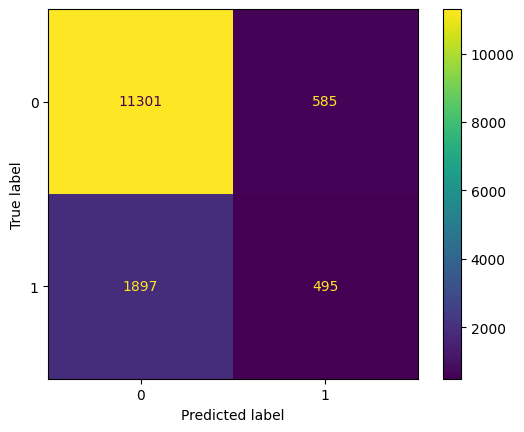

In [3]:
# Import necessary libraries
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# Display KNN model evaluation
display(Markdown("### KNN Model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Evaluate the model
print("Accuracy Score for KNN:")
print(accuracy_score(y_test, y_pred_knn))
print("Classification Report for KNN:")
print(classification_report(y_test, y_pred_knn, labels=[0, 1], zero_division=0))
# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, labels=[0, 1])
plt.show()

In [4]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV
# Display hyperparameter tuning information
display(Markdown("### Hyperparameter Tuning for KNN"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Define the parameter grid for hyperparameter tuning
param_grid = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan', 'minkowski']}
# Initialize GridSearchCV with the KNN model and parameter grid
grid_search_knn = GridSearchCV(KNeighborsClassifier(), param_grid, refit=True, verbose=2, cv=3)
# Fit the model to the training data
grid_search_knn.fit(X_train, y_train)
# Display the best parameters and best score
print(f"Best Parameters: {grid_search_knn.best_params_}")
print(f"Best Score: {grid_search_knn.best_score_}")
# Make predictions with the best estimator
y_pred_knn_tuned = grid_search_knn.best_estimator_.predict(X_test)

### Hyperparameter Tuning for KNN

Date: 2026-10-26

Student ID: abrgeb8774

Fitting 3 folds for each of 24 candidates, totalling 72 fits
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   4.9s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   3.4s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   3.3s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   4.0s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   3.3s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   3.2s
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   4.0s
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   3.3s
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   3.3s
[CV] END ..metric=euclidean, n_neighbors=5, weights=distance; total time=   3.8s
[CV] END ..metric=euclidean, n_neighbors=5, weights=distance; total time=   3.6s
[CV] END ..metric=euclidean, n_neighbors=5, weig

### Evaluate the Tuned KNN Model

Date: 2026-10-26

Student ID: abrgeb8774

Accuracy Score for Tuned KNN:
0.8405238828967643
Classification Report for Tuned KNN:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91     11886
           1       0.57      0.19      0.28      2392

    accuracy                           0.84     14278
   macro avg       0.71      0.58      0.60     14278
weighted avg       0.81      0.84      0.81     14278



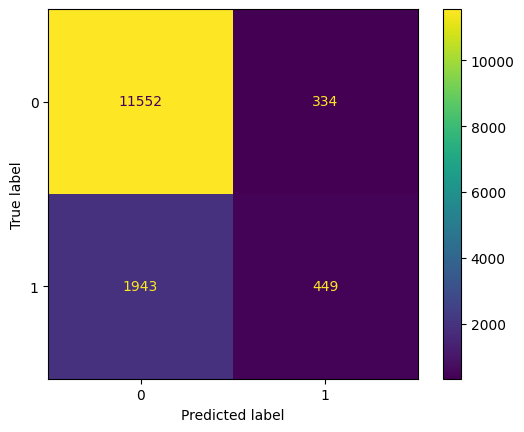

In [5]:
# Import necessary libraries
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# Display tuned KNN model evaluation
display(Markdown("### Evaluate the Tuned KNN Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Evaluate the tuned model
print("Accuracy Score for Tuned KNN:")
print(accuracy_score(y_test, y_pred_knn_tuned))
print("Classification Report for Tuned KNN:")
print(classification_report(y_test, y_pred_knn_tuned, labels=[0, 1], zero_division=0))
# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn_tuned, labels=[0, 1])
plt.show()

### Visualizing the Tuned KNN Model

Date: 2026-10-26

Student ID: abrgeb8774

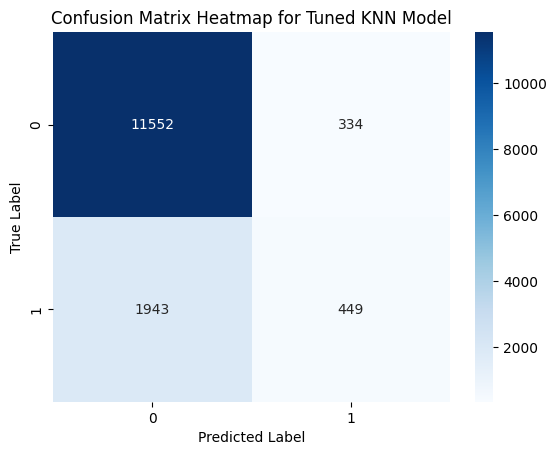

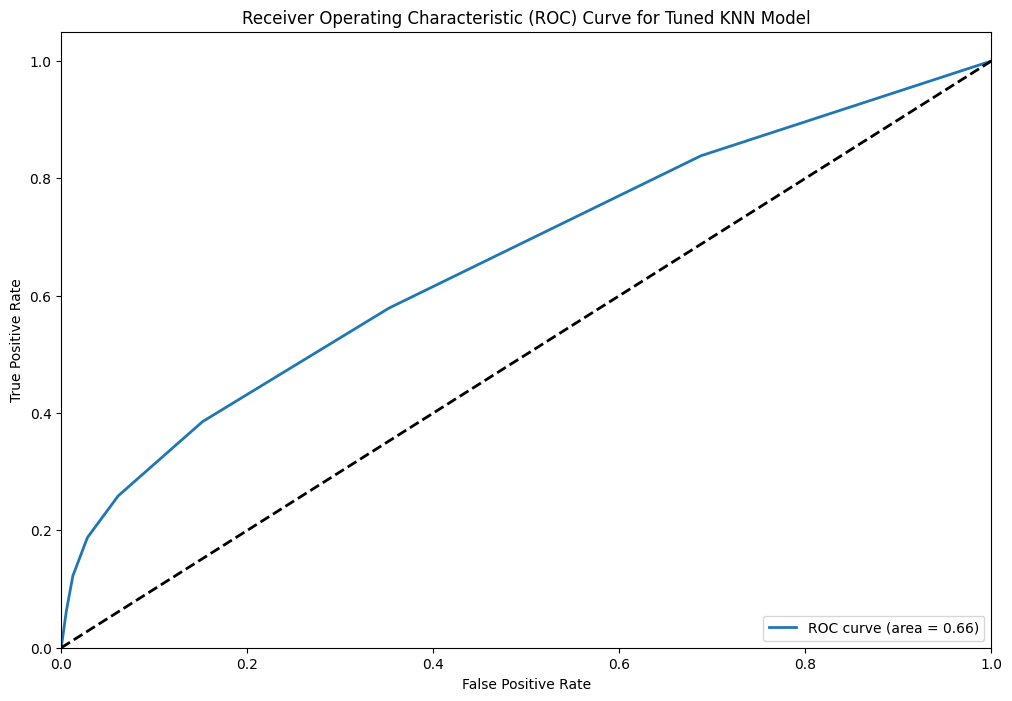

In [6]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
display(Markdown("### Visualizing the Tuned KNN Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Create a confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred_knn_tuned, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix Heatmap for Tuned KNN Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
# Calculate ROC curve and AUC score
y_pred_proba = grid_search_knn.best_estimator_.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)
# Plot the ROC curve
plt.figure(figsize=(12, 8))
plt.plot(fpr, tpr, lw=2, label=f'ROC curve (area = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Tuned KNN Model')
plt.legend(loc="lower right")
plt.show()